#Deep Learning para visión de computadoras
##Lab 2.2 Segmentación semántica

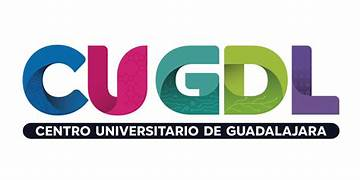

# Objetivo
Calcular IoU por clase y mIoU a mano a partir de la matriz de confusión y verificar con torchmetrics.
Construir una U-Net desde cero y medir qué aportan las conexiones de salto.
Comparar tres funciones de pérdida: entropía cruzada, Dice y su combinación.
Secuencias de video: CNN estática vs. CNN-LSTM

In [1]:
%pip install -q torchmetrics

/Users/vikingo/Documents/UDG2/5toSem/DeepLearning/.venv/bin/python3: No module named pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import time, copy
import os
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader, Dataset, Subset
import torchmetrics
import torchvision
import torchvision.transforms as T
from torchmetrics.classification import MulticlassJaccardIndex, MulticlassConfusionMatrix

SEED = 2
def fijar_semilla(s=SEED):
    np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
fijar_semilla()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DEVICE, "·", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU (más lento, pero funciona)")
print("torch", torch.__version__, "· torchmetrics", torchmetrics.__version__)

NOMBRES = ["fondo", "círculo", "cuadrado", "triángulo"]
N_CLASES = len(NOMBRES)
TAM = 64                       # las imágenes son de 64 x 64 píxeles

Dispositivo: cpu · CPU (más lento, pero funciona)
torch 2.14.1 · torchmetrics 1.9.0


---
# PARTE A

En clasificación, una imagen tiene **una** etiqueta. En segmentación semántica, una imagen de $H\times W$ tiene **$H\cdot W$ etiquetas**:

El conjunto de datos de mascotas Oxford- IIIT ( Parkhi et al, 2012 ). El conjunto de datos consta de imágenes de 37 razas de mascotas, con 200 imágenes por raza (~100 cada una en las divisiones de entrenamiento y prueba). Cada imagen incluye las etiquetas correspondientes y las máscaras de píxeles.

    El dataset contiene imágenes de mascotas y máscaras de segmentación de 3 clases:
    
    Clase 1: Mascota (Foreground)
    Clase 2: Fondo (Background)
    Clase 3: Borde / Contorno ambiguo\

In [3]:
TAM = 128
NOMBRES_CLASES = ["Mascota", "Fondo", "Borde"]
N_CLASES = len(NOMBRES_CLASES)

# Transformación para la imagen (RGB -> Normalización estándar de ImageNet)
transform_img = T.Compose([
    T.Resize((TAM, TAM)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Transformación para la máscara (Interpolación NEAREST para preservar enteros) reescalado, garantizando que no se generen valores intermedios artificiales entre categorías.
#Por conveniencia, reste 1 de la máscara de segmentación, lo que da como resultado etiquetas que son: {0, 1, 2}.
def transform_mask(mask):
    mask = mask.resize((TAM, TAM), resample=Image.NEAREST)
    mask_arr = np.array(mask, dtype=np.int64) - 1  # Pasar de {1,2,3} a {0,1,2}
    return torch.as_tensor(mask_arr, dtype=torch.long)

# Descargar dataset oficial vía torchvision
train_raw = torchvision.datasets.OxfordIIITPet(
    root="./data", split="trainval", target_types="segmentation", download=True,
    transform=transform_img, target_transform=transform_mask
)
test_raw = torchvision.datasets.OxfordIIITPet(
    root="./data", split="test", target_types="segmentation", download=True,
    transform=transform_img, target_transform=transform_mask
)

# Subconjuntos optimizados para una sesión interactiva de clase (rápida convergencia)
train_ds = Subset(train_raw, range(1000))
val_ds = Subset(test_raw, range(250))

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=0)

print(f"Imágenes de entrenamiento: {len(train_ds)} | Validación: {len(val_ds)}")

Imágenes de entrenamiento: 1000 | Validación: 250


máscaras reales codificadas mediante un mapa de color cualitativo (Verde = Mascota, Negro = Fondo, Rojo = Borde):

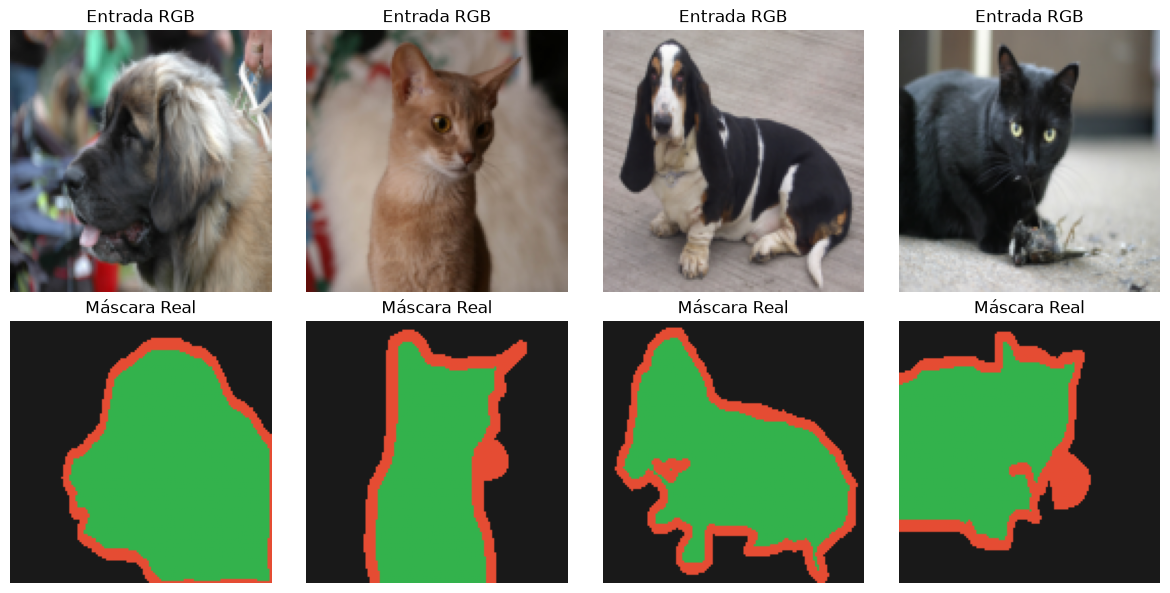

In [4]:
def desnormalizar(tensor):
    img = tensor.clone().cpu().permute(1, 2, 0).numpy()
    img = img * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406]
    return np.clip(img, 0, 1)

PALETA_PETS = np.array([[0.2, 0.7, 0.3], [0.1, 0.1, 0.1], [0.9, 0.3, 0.2]])

imgs, masks = next(iter(train_loader))
fig, axs = plt.subplots(2, 4, figsize=(12, 6))
for i in range(4):
    axs[0, i].imshow(desnormalizar(imgs[i]))
    axs[0, i].set_title("Entrada RGB")
    axs[0, i].axis("off")

    axs[1, i].imshow(PALETA_PETS[masks[i].numpy()])
    axs[1, i].set_title("Máscara Real")
    axs[1, i].axis("off")
plt.tight_layout()
plt.show()

# 2. ARQUITECTURA DE LA RED: U-NET COMPACTA DESDE CEROLa red implementa una estructura simétrica compuesta por:   

1.   Bloque Doble de Convolución: Encapsula la secuencia $\text {Conv2D} \rightarrow \text{BatchNorm} \rightarrow \text{ReLU}$ por duplicado, manteniendo dimensiones espaciales mediante relleno (padding $= 1$).

2.   Trayectoria de Contracción (Encoder): Reduce periódicamente la resolución a la mitad con operaciones de agrupamiento máximo (MaxPool2d) mientras incrementa la profundidad de canales semánticos.   
3. Cuello de Botella (Bottleneck): El punto de mayor compresión espacial ($16 \times 16$) y máxima abstracción de características.   
4. Trayectoria de Expansión (Decoder): Aplica convoluciones transpuestas (ConvTranspose2d) con factor de escala $\times 2$ y realiza la fusión por concatenación (torch.cat) de las activaciones correspondientes del codificador.   
5. Capa de Salida: Una convolución $1 \times 1$ que reduce los 32 canales residuales a 3 logits correspondientes a las clases del problema.  

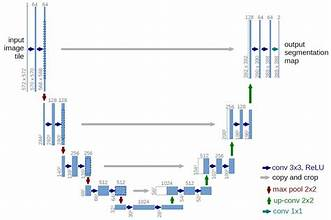

In [5]:
class BloqueDobleConv(nn.Module):
    """(Conv2d -> BatchNorm -> ReLU) * 2"""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.net(x)

class UNetCompacta(nn.Module):
    def __init__(self, in_channels=3, num_classes=3):
        super().__init__()
        # --- ENCODER ---
        self.enc1 = BloqueDobleConv(in_channels, 32)      # Entrada: 128x128
        self.pool1 = nn.MaxPool2d(2, 2)                   # -> 64x64

        self.enc2 = BloqueDobleConv(32, 64)               # -> 64x64
        self.pool2 = nn.MaxPool2d(2, 2)                   # -> 32x32

        self.enc3 = BloqueDobleConv(64, 128)              # -> 32x32
        self.pool3 = nn.MaxPool2d(2, 2)                   # -> 16x16

        # --- BOTTLENECK ---
        self.bottleneck = BloqueDobleConv(128, 256)       # -> 16x16

        # --- DECODER & SKIP CONNECTIONS ---
        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2) # -> 32x32
        self.dec3 = BloqueDobleConv(256, 128)             # 128 (skip) + 128 = 256

        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)   # -> 64x64
        self.dec2 = BloqueDobleConv(128, 64)              # 64 (skip) + 64 = 128

        self.up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)    # -> 128x128
        self.dec1 = BloqueDobleConv(64, 32)               # 32 (skip) + 32 = 64

        # Proyección final lineal a nivel de píxel
        self.out_conv = nn.Conv2d(32, num_classes, kernel_size=1)

    def forward(self, x):
        # Paso por el Encoder
        s1 = self.enc1(x)
        p1 = self.pool1(s1)

        s2 = self.enc2(p1)
        p2 = self.pool2(s2)

        s3 = self.enc3(p2)
        p3 = self.pool3(s3)

        # Cuello de botella
        b = self.bottleneck(p3)

        # Paso por el Decoder con Skip Connections (torch.cat)
        d3 = self.up3(b)
        d3 = torch.cat([d3, s3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, s2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, s1], dim=1)
        d1 = self.dec1(d1)

        return self.out_conv(d1)

modelo = UNetCompacta(in_channels=3, num_classes=3).to(DEVICE)
print("Arquitectura instanciada. Parámetros totales:", sum(p.numel() for p in modelo.parameters()))

Arquitectura instanciada. Parámetros totales: 1927075


---
# PARTE B

Sean $TP_c$, $FP_c$, $FN_c$ los píxeles de la clase $c$ acertados, falsamente asignados a $c$ y omitidos, respectivamente. Para cada clase:

$$\mathrm{IoU}_c=\frac{TP_c}{TP_c+FP_c+FN_c}\qquad \mathrm{Dice}_c=\frac{2\,TP_c}{2\,TP_c+FP_c+FN_c}\qquad \mathrm{mIoU}=\frac{1}{C}\sum_{c=1}^{C}\mathrm{IoU}_c$$

Todo sale de la **matriz de confusión** de píxeles: la diagonal contiene los $TP_c$; la suma de la fila $c$ menos la diagonal son los $FN_c$; la suma de la columna $c$ menos la diagonal son los $FP_c$. Aquí las filas son la clase real y las columnas la predicha.

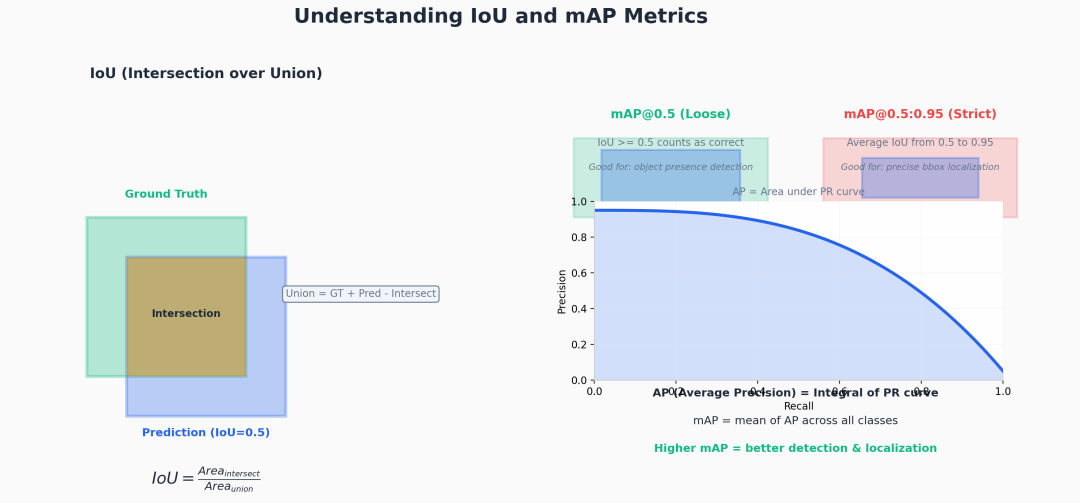

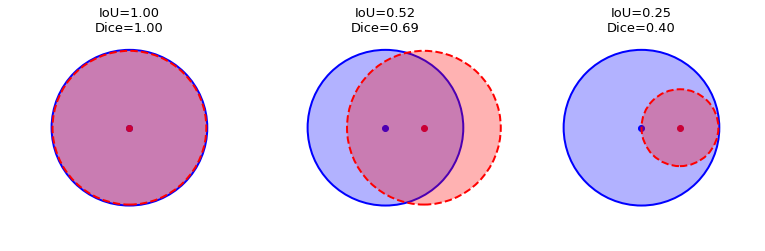

Revisar: https://ilmonteux.github.io/2019/05/10/segmentation-metrics.html


Para optimizar adecuadamente la segmentación semántica frente al desbalance de clases (por ejemplo, el borde contiene considerablemente menos píxeles que el fondo), se combinan dos objetivos complementarios:   

Cross-Entropy Loss ($\mathcal{L}_{\text{CE}}$): Evalúa la distribución de probabilidad generada independientemente en cada posición $(i, j)$ del mapa de píxeles.   

Dice Loss ($\mathcal{L}_{\text{Dice}}$): Mide el solapamiento volumétrico entre la máscara binarizada y la predicción probabilística:

   $$\text{Dice} = \frac{2 \vert{}P \cap T\vert{}}{\vert{}P\vert{} + \vert{}T\vert{}} = \frac{2 \sum p_i t_i}{\sum p_i^2 + \sum t_i^2}$$   Pérdida Híbrida Total:$$\mathcal{L}_{\text{Total}} = \mathcal{L}_{\text{CE}} + \mathcal{L}_{\text{Dice}}$$

In [6]:
class DiceLoss(nn.Module):
    def __init__(self, eps=1e-6):
        super().__init__()
        self.eps = eps

    def forward(self, logits, targets):
        num_classes = logits.shape[1]
        probs = F.softmax(logits, dim=1)

        # One-hot encoding de targets a dimensiones [B, C, H, W]
        targets_one_hot = F.one_hot(targets, num_classes=num_classes).permute(0, 3, 1, 2).float()

        # Aplanar dimensiones espaciales para el cálculo vectorial
        probs = probs.contiguous().view(probs.shape[0], num_classes, -1)
        targets_one_hot = targets_one_hot.contiguous().view(targets_one_hot.shape[0], num_classes, -1)

        interseccion = (probs * targets_one_hot).sum(dim=2)
        union = probs.sum(dim=2) + targets_one_hot.sum(dim=2)

        dice = (2. * interseccion + self.eps) / (union + self.eps)
        return 1.0 - dice.mean()

# Instanciación de pérdidas
ce_fn = nn.CrossEntropyLoss()
dice_fn = DiceLoss()

def loss_combinada(logits, targets):
    return ce_fn(logits, targets) + dice_fn(logits, targets)

#ENTRENAMIENTO

In [7]:
EPOCHS = 6
optimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3)

print("--- Iniciando Entrenamiento U-Net ---")
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    modelo.train()
    loss_acumulada = 0.0

    for imgs, masks in train_loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)

        optimizador.zero_grad()
        logits = modelo(imgs)
        loss = loss_combinada(logits, masks)
        loss.backward()
        optimizador.step()

        loss_acumulada += loss.item()

    tiempo_epoca = time.time() - t0
    loss_promedio = loss_acumulada / len(train_loader)
    print(f"Época {epoch}/{EPOCHS} | Loss: {loss_promedio:.4f} | Tiempo: {tiempo_epoca:.1f}s")

--- Iniciando Entrenamiento U-Net ---


Época 1/6 | Loss: 1.2579 | Tiempo: 68.5s


Época 2/6 | Loss: 1.0186 | Tiempo: 71.1s


Época 3/6 | Loss: 0.9447 | Tiempo: 72.9s


Época 4/6 | Loss: 0.8628 | Tiempo: 72.3s


Época 5/6 | Loss: 0.8129 | Tiempo: 73.3s


Época 6/6 | Loss: 0.7493 | Tiempo: 73.9s


IoU, mIoU Y MATRIZ DE CONFUSIÓN

Calculo de forma desacoplada el índice de Jaccard (Intersection over Union) para cada una de las clases, su promedio macro (mIoU) y la matriz de confusión espacial de píxeles empleando torchmetrics:   $$\text{IoU}_c = \frac{TP_c}{TP_c + FP_c + FN_c}$$

In [8]:
metric_iou_clase = MulticlassJaccardIndex(num_classes=N_CLASES, average=None).to(DEVICE)
metric_iou_macro = MulticlassJaccardIndex(num_classes=N_CLASES, average="macro").to(DEVICE)
metric_confusion = MulticlassConfusionMatrix(num_classes=N_CLASES).to(DEVICE)

modelo.eval()
with torch.no_grad():
    for imgs, masks in val_loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        logits = modelo(imgs)
        preds = logits.argmax(dim=1)

        metric_iou_clase.update(preds, masks)
        metric_iou_macro.update(preds, masks)
        metric_confusion.update(preds, masks)

ious = metric_iou_clase.compute().cpu().numpy()
miou = metric_iou_macro.compute().item()
cm = metric_confusion.compute().cpu().numpy()

tabla_eval = pd.DataFrame({
    "Clase": NOMBRES_CLASES,
    "IoU (Jaccard)": [round(val, 4) for val in ious]
})
display(tabla_eval)
print(f"\nMean IoU (mIoU): {miou:.4f}")

print("\nMatriz de Confusión de Píxeles:\n", cm)

,Clase,IoU (Jaccard)
0,Mascota,0.6053
1,Fondo,0.7804
2,Borde,0.3554



Mean IoU (mIoU): 0.5804

Matriz de Confusión de Píxeles:
 [[ 836947  265379   72147]
 [  96170 2208324   56919]
 [ 112106  203058  244950]]


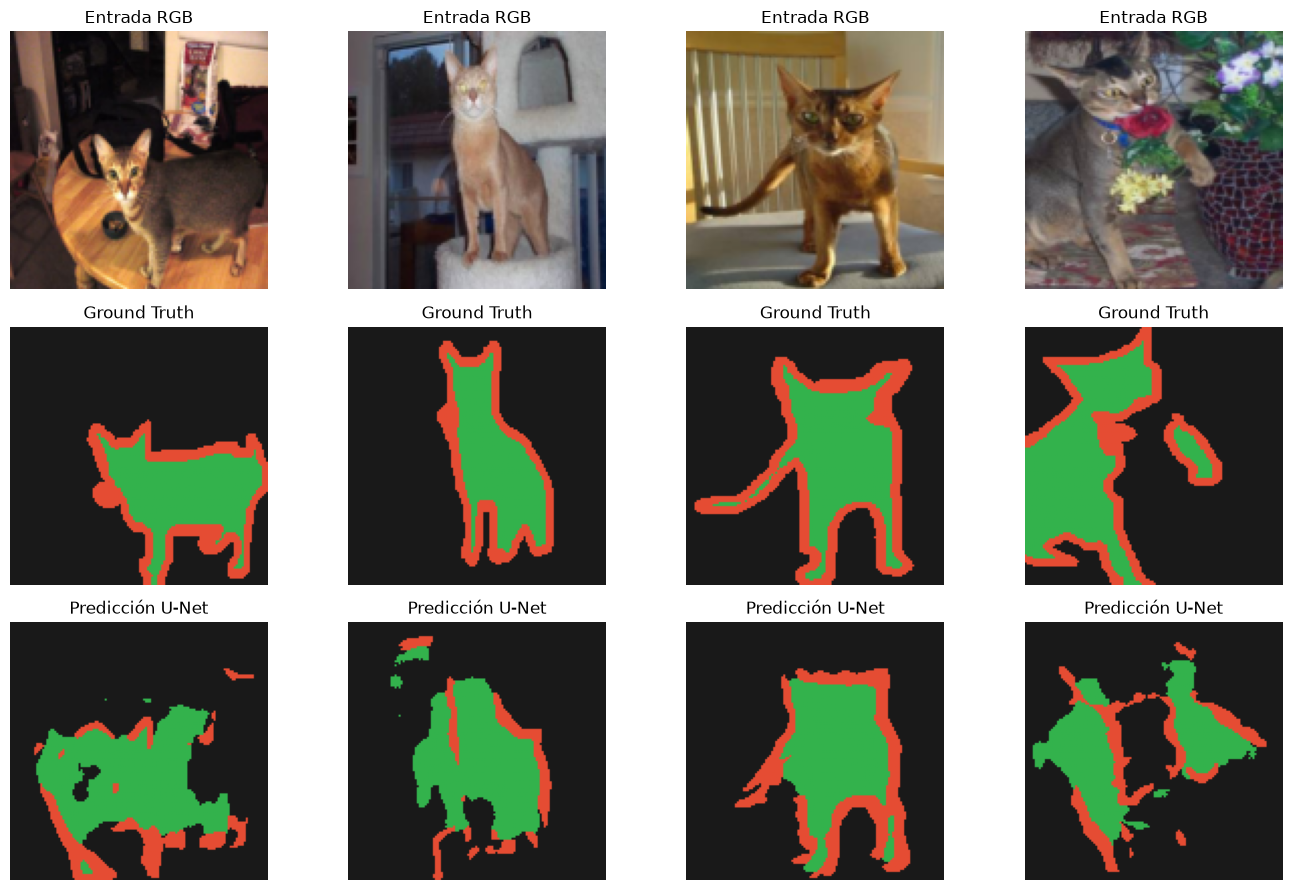

In [9]:
imgs, masks = next(iter(val_loader))
imgs_dev = imgs.to(DEVICE)

modelo.eval()
with torch.no_grad():
    preds = modelo(imgs_dev).argmax(dim=1).cpu()

fig, axs = plt.subplots(3, 4, figsize=(14, 9))
for i in range(4):
    axs[0, i].imshow(desnormalizar(imgs[i]))
    axs[0, i].set_title("Entrada RGB")
    axs[0, i].axis("off")

    axs[1, i].imshow(PALETA_PETS[masks[i].numpy()])
    axs[1, i].set_title("Ground Truth")
    axs[1, i].axis("off")

    axs[2, i].imshow(PALETA_PETS[preds[i].numpy()])
    axs[2, i].set_title("Predicción U-Net")
    axs[2, i].axis("off")
plt.tight_layout()
plt.show()

### Actividad
Clases desequilibradas y ponderación de clases

Los conjuntos de datos para segmentación semántica pueden estar muy desequilibrados; esto significa que los píxeles correspondientes a determinadas clases pueden aparecer con mayor frecuencia en las imágenes que los de otras clases. Dado que los problemas de segmentación pueden abordarse como problemas de clasificación a nivel de píxel, es posible gestionar este desequilibrio mediante la ponderación de la función de pérdida. Se trata de una solución sencilla y elegante para este tipo de situaciones. Para obtener más información, consulte el tutorial sobre [Classification on imbalanced data](../structured_data/imbalanced_data.ipynb) tutorial to learn more.

To [avoid ambiguity](https://github.com/keras-team/keras/issues/3653#issuecomment-243939748), `Model.fit` does not support the `class_weight` argument for targets with 3+ dimensions.

,clase,píxeles,fracción
0,Mascota,4684013,0.2859
1,Fondo,9738252,0.5944
2,Borde,1961735,0.1197


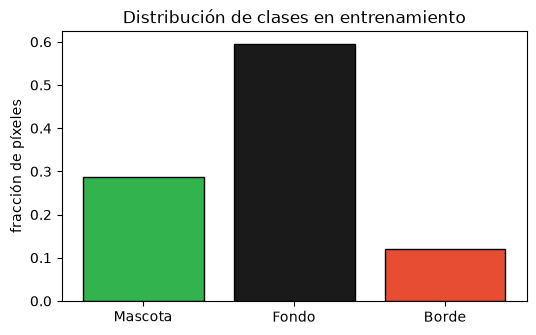

La clase dominante (Fondo) ocupa 59.4 % de los píxeles; la minoritaria (Borde) solo 12.0 %.


In [10]:
# Gráfica de barras de desbalance (Oxford-IIIT Pet, subconjunto de entrenamiento)
# Se cuentan píxeles leyendo solo las máscaras (sin pasar por la red ni cargar las imágenes RGB).
conteo = np.zeros(N_CLASES, dtype=np.int64)
for idx in train_ds.indices:
    mascara = transform_mask(Image.open(train_raw._segs[idx]))
    conteo += np.bincount(mascara.flatten().numpy(), minlength=N_CLASES)
frac = conteo / conteo.sum()
tabla_px = pd.DataFrame({"clase": NOMBRES_CLASES, "píxeles": conteo, "fracción": frac.round(4)})
display(tabla_px)

plt.figure(figsize=(6, 3.5)); plt.bar(NOMBRES_CLASES, frac, color=PALETA_PETS, edgecolor="k")
plt.ylabel("fracción de píxeles"); plt.title("Distribución de clases en entrenamiento"); plt.show()
clase_dom = int(frac.argmax())
print(f"La clase dominante ({NOMBRES_CLASES[clase_dom]}) ocupa {frac[clase_dom]*100:.1f} % de los píxeles; "
      f"la minoritaria ({NOMBRES_CLASES[int(frac.argmin())]}) solo {frac.min()*100:.1f} %.")

In [11]:
def evaluar(modelo_x, loader, n_clases):
    """IoU por clase, mIoU (macro), exactitud de píxeles y matriz de confusión."""
    m_clase = MulticlassJaccardIndex(num_classes=n_clases, average=None).to(DEVICE)
    m_conf = MulticlassConfusionMatrix(num_classes=n_clases).to(DEVICE)
    modelo_x.eval()
    with torch.no_grad():
        for imgs, masks in loader:
            preds = modelo_x(imgs.to(DEVICE)).argmax(dim=1)
            m_clase.update(preds, masks.to(DEVICE))
            m_conf.update(preds, masks.to(DEVICE))
    ious = m_clase.compute().cpu().numpy()
    cm = m_conf.compute().cpu().numpy()
    return ious, float(ious.mean()), float(np.trace(cm) / cm.sum()), cm

ious_base, miou_base, acc_base, cm_base = evaluar(modelo, val_loader, N_CLASES)

# Clasificador trivial: predecir siempre la clase dominante en validación
frac_val = cm_base.sum(axis=1) / cm_base.sum()
dom = int(frac_val.argmax())
acc_trivial = float(frac_val[dom])
ious_trivial = np.zeros(N_CLASES); ious_trivial[dom] = frac_val[dom]   # IoU de la clase dominante = su fracción
recall_base = np.diag(cm_base) / cm_base.sum(axis=1)

tabla_acc = pd.DataFrame({
    "Clase": NOMBRES_CLASES,
    "% píxeles (val)": (frac_val * 100).round(1),
    "Recall U-Net": recall_base.round(3),
    "IoU U-Net": ious_base.round(3),
    f"IoU 'todo {NOMBRES_CLASES[dom]}'": ious_trivial.round(3),
})
display(tabla_acc)
print(f"Exactitud de píxeles U-Net           : {acc_base:.4f}   | mIoU: {miou_base:.4f}")
print(f"Exactitud 'siempre {NOMBRES_CLASES[dom]}'  : {acc_trivial:.4f}   | mIoU: {ious_trivial.mean():.4f}")

,Clase,% píxeles (val),Recall U-Net,IoU U-Net,IoU 'todo Fondo'
0,Mascota,28.7,0.713,0.605,0.000
1,Fondo,57.7,0.935,0.780,0.577
2,Borde,13.7,0.437,0.355,0.000


Exactitud de píxeles U-Net           : 0.8033   | mIoU: 0.5804
Exactitud 'siempre Fondo'  : 0.5765   | mIoU: 0.1922


Con la exactitud obtenida explica por qué la exactitud de píxeles **no es una métrica adecuada** para segmentación cuando una clase domina.

**Respuesta.** La U-Net obtiene una exactitud de píxeles de **0.803**, que parece buena, pero un clasificador trivial que predice siempre `Fondo` ya obtiene **0.577** sin mirar la imagen. La exactitud cuenta cada píxel por igual, así que está dominada por la clase que más píxeles tiene (el fondo ocupa 57.7 % en validación): se puede subir acertando el fondo mientras se falla en las clases pequeñas. La tabla lo muestra: el recall de `Fondo` es 0.935, pero el de `Borde` es solo **0.437** (IoU 0.355) y el de `Mascota` 0.713; el mIoU, que promedia las clases por igual, es 0.580. Además, el clasificador trivial tiene exactitud 0.577 pero mIoU de 0.192 (IoU 0 en dos de tres clases), lo que la exactitud no revela. Por eso en segmentación se reporta IoU por clase / mIoU (o Dice), que penalizan tanto FP como FN de cada clase y no se inflan por el tamaño de la clase dominante.

El efecto es más claro en Kvasir-SEG (abajo), donde el fondo ocupa 84.6 % y la U-Net entrenada tiene exactitud 0.826, **menor** que la del clasificador "todo fondo" (0.846), aunque segmenta pólipos con IoU 0.42 y el trivial con 0.

**Ponderación de la pérdida.** Como `Model.fit` de Keras no admite `class_weight` en blancos 3D, se aplica el peso directamente en la entropía cruzada por píxel: `nn.CrossEntropyLoss(weight=w)`. Se usa el inverso de la frecuencia de cada clase (normalizado para que sumen `N_CLASES`), de modo que un píxel de la clase minoritaria cuesta más que uno de la dominante. Se entrena un modelo nuevo con la misma semilla, épocas y términos Dice, y se compara contra el modelo sin ponderar.

In [12]:
pesos = (1.0 / frac); pesos = pesos / pesos.sum() * N_CLASES
print("Pesos por clase:", dict(zip(NOMBRES_CLASES, pesos.round(3))))

ce_pond = nn.CrossEntropyLoss(weight=torch.tensor(pesos, dtype=torch.float32, device=DEVICE))
def loss_ponderada(logits, targets):
    return ce_pond(logits, targets) + dice_fn(logits, targets)

fijar_semilla()
modelo_pond = UNetCompacta(in_channels=3, num_classes=N_CLASES).to(DEVICE)
opt_pond = torch.optim.Adam(modelo_pond.parameters(), lr=1e-3)

print("--- Entrenamiento U-Net con CE ponderada + Dice ---")
for epoch in range(1, EPOCHS + 1):
    t0 = time.time(); modelo_pond.train(); acum = 0.0
    for imgs, masks in train_loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        opt_pond.zero_grad()
        loss = loss_ponderada(modelo_pond(imgs), masks)
        loss.backward(); opt_pond.step()
        acum += loss.item()
    print(f"Época {epoch}/{EPOCHS} | Loss: {acum/len(train_loader):.4f} | Tiempo: {time.time()-t0:.1f}s")

ious_p, miou_p, acc_p, cm_p = evaluar(modelo_pond, val_loader, N_CLASES)
recall_p = np.diag(cm_p) / cm_p.sum(axis=1)
comparacion = pd.DataFrame({
    "Clase": NOMBRES_CLASES,
    "IoU sin ponderar": ious_base.round(4), "IoU ponderado": ious_p.round(4),
    "Recall sin ponderar": recall_base.round(3), "Recall ponderado": recall_p.round(3),
})
display(comparacion)
print(f"mIoU           : {miou_base:.4f} (sin ponderar) -> {miou_p:.4f} (ponderado)")
print(f"Exactitud píxel: {acc_base:.4f} (sin ponderar) -> {acc_p:.4f} (ponderado)")

Pesos por clase: {'Mascota': np.float64(0.775), 'Fondo': np.float64(0.373), 'Borde': np.float64(1.852)}
--- Entrenamiento U-Net con CE ponderada + Dice ---


Época 1/6 | Loss: 1.3725 | Tiempo: 74.9s


Época 2/6 | Loss: 1.1229 | Tiempo: 73.4s


Época 3/6 | Loss: 1.0159 | Tiempo: 73.6s


Época 4/6 | Loss: 0.9319 | Tiempo: 72.7s


Época 5/6 | Loss: 0.8957 | Tiempo: 72.9s


Época 6/6 | Loss: 0.8538 | Tiempo: 74.1s


,Clase,IoU sin ponderar,IoU ponderado,Recall sin ponderar,Recall ponderado
0,Mascota,0.6053,0.5982,0.713,0.670
1,Fondo,0.7804,0.7956,0.935,0.894
2,Borde,0.3554,0.4149,0.437,0.694


mIoU           : 0.5804 (sin ponderar) -> 0.6029 (ponderado)
Exactitud píxel: 0.8033 (sin ponderar) -> 0.8024 (ponderado)


**Resultado.** Con pesos inversos a la frecuencia (`Mascota` 0.775, `Fondo` 0.373, `Borde` 1.852) el mIoU sube de 0.580 a **0.603**, y la mejora viene de la clase minoritaria: el IoU de `Borde` pasa de 0.355 a **0.415** y su recall de 0.437 a **0.694**. El costo es que el modelo predice `Borde` más a menudo, así que baja el recall de `Fondo` (0.935 → 0.894) y de `Mascota` (0.713 → 0.670) y el IoU de `Mascota` baja ligeramente (0.605 → 0.598). La exactitud de píxeles casi no cambia (0.803 → 0.802): el cambio en la calidad de la segmentación es invisible para esa métrica y sí aparece en IoU/recall por clase.

Matiz: es una sola corrida por configuración (semilla fija, 6 épocas, 1000 imágenes), así que la diferencia de +0.02 mIoU indica la tendencia pero no está medida con varias semillas. El desbalance en Pets es moderado (12 % vs 59 %); con desbalances mayores, como el de pólipos, la ponderación importa más.

### Actividad
Otros datasets
[Carvana](https://www.kaggle.com/c/carvana-image-masking-challenge/overview) image masking challenge hosted on Kaggle.

DSB 2018
# https://datasets.simula.no/kvasir-seg/
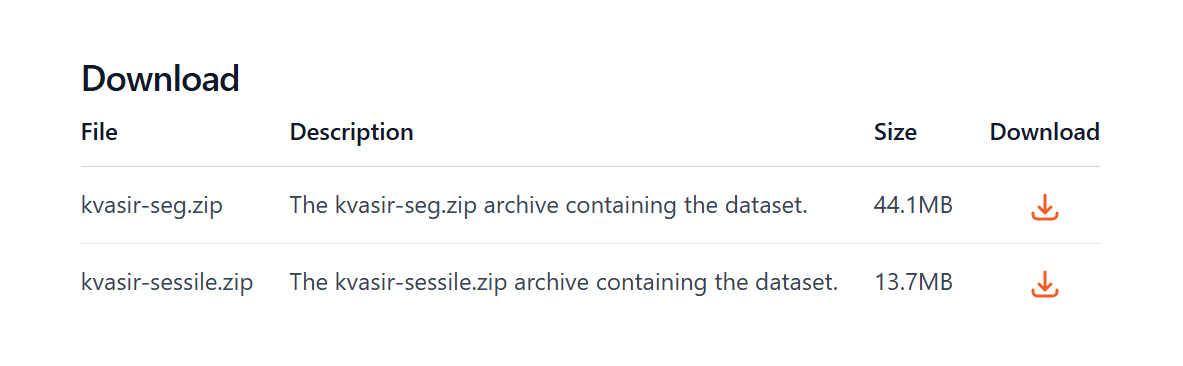

**Carvana.** Este dataset solo se obtiene desde Kaggle y exige cuenta, token de API (`~/.kaggle/kaggle.json`) y aceptar las reglas de la competencia, por lo que no se puede descargar automáticamente en este notebook. Con las credenciales configuradas bastaría:

```bash
kaggle competitions download -c carvana-image-masking-challenge
```

Es un problema de segmentación binaria (auto vs. fondo), igual que el de abajo. Como alternativa de libre descarga se usa **Kvasir-SEG** (1000 imágenes de endoscopía con máscara de pólipos, enlazado en la celda de arriba), con exactamente la misma U-Net y la misma pérdida CE + Dice.

In [13]:
import zipfile, urllib.request

KVASIR_DIR = "./data/kvasir"
KVASIR_ZIP = f"{KVASIR_DIR}/kvasir-seg.zip"
os.makedirs(KVASIR_DIR, exist_ok=True)
if not os.path.exists(KVASIR_ZIP):
    urllib.request.urlretrieve("https://datasets.simula.no/downloads/kvasir-seg.zip", KVASIR_ZIP)
if not os.path.isdir(f"{KVASIR_DIR}/Kvasir-SEG"):
    with zipfile.ZipFile(KVASIR_ZIP) as z:
        z.extractall(KVASIR_DIR)
print("Imágenes:", len(os.listdir(f"{KVASIR_DIR}/Kvasir-SEG/images")), "| Máscaras:", len(os.listdir(f"{KVASIR_DIR}/Kvasir-SEG/masks")))

Imágenes: 1000 | Máscaras: 1000


In [14]:
NOMBRES_K = ["Fondo", "Pólipo"]
PALETA_K = np.array([[0.1, 0.1, 0.1], [0.9, 0.8, 0.2]])
raiz_k = f"{KVASIR_DIR}/Kvasir-SEG"
archivos_k = sorted(os.listdir(f"{raiz_k}/images"))

def cargar_par(nombre):
    img = Image.open(f"{raiz_k}/images/{nombre}").convert("RGB")
    msk = Image.open(f"{raiz_k}/masks/{nombre}").convert("L").resize((TAM, TAM), resample=Image.NEAREST)
    return transform_img(img), torch.as_tensor((np.array(msk) > 127).astype(np.int64))

pares = [cargar_par(n) for n in archivos_k]
X_k = torch.stack([p[0] for p in pares]); Y_k = torch.stack([p[1] for p in pares])
perm = torch.randperm(len(X_k), generator=torch.Generator().manual_seed(SEED))
n_tr = int(0.8 * len(X_k))
tr_k = DataLoader(TensorDataset(X_k[perm[:n_tr]], Y_k[perm[:n_tr]]), batch_size=16, shuffle=True)
va_k = DataLoader(TensorDataset(X_k[perm[n_tr:]], Y_k[perm[n_tr:]]), batch_size=16)
frac_k = torch.bincount(Y_k.flatten(), minlength=2).numpy() / Y_k.numel()
print(f"Entrenamiento: {n_tr} | Validación: {len(X_k) - n_tr} | Fondo {frac_k[0]*100:.1f} % · Pólipo {frac_k[1]*100:.1f} %")

fijar_semilla()
modelo_k = UNetCompacta(in_channels=3, num_classes=2).to(DEVICE)
opt_k = torch.optim.Adam(modelo_k.parameters(), lr=1e-3)
for epoch in range(1, EPOCHS + 1):
    t0 = time.time(); modelo_k.train(); acum = 0.0
    for imgs, masks in tr_k:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        opt_k.zero_grad()
        loss = loss_combinada(modelo_k(imgs), masks)
        loss.backward(); opt_k.step()
        acum += loss.item()
    print(f"Época {epoch}/{EPOCHS} | Loss: {acum/len(tr_k):.4f} | Tiempo: {time.time()-t0:.1f}s")

ious_k, miou_k, acc_k, cm_k = evaluar(modelo_k, va_k, 2)
display(pd.DataFrame({"Clase": NOMBRES_K, "IoU": ious_k.round(4)}))
print(f"mIoU: {miou_k:.4f} | Exactitud de píxeles: {acc_k:.4f} | Exactitud 'todo fondo': {frac_k[0]:.4f}")

Entrenamiento: 800 | Validación: 200 | Fondo 84.6 % · Pólipo 15.4 %


Época 1/6 | Loss: 0.9395 | Tiempo: 54.8s


Época 2/6 | Loss: 0.7153 | Tiempo: 53.5s


Época 3/6 | Loss: 0.6351 | Tiempo: 54.0s


Época 4/6 | Loss: 0.5737 | Tiempo: 54.1s


Época 5/6 | Loss: 0.5273 | Tiempo: 53.8s


Época 6/6 | Loss: 0.4924 | Tiempo: 53.5s


,Clase,IoU
0,Fondo,0.8012
1,Pólipo,0.4209


mIoU: 0.6111 | Exactitud de píxeles: 0.8263 | Exactitud 'todo fondo': 0.8461


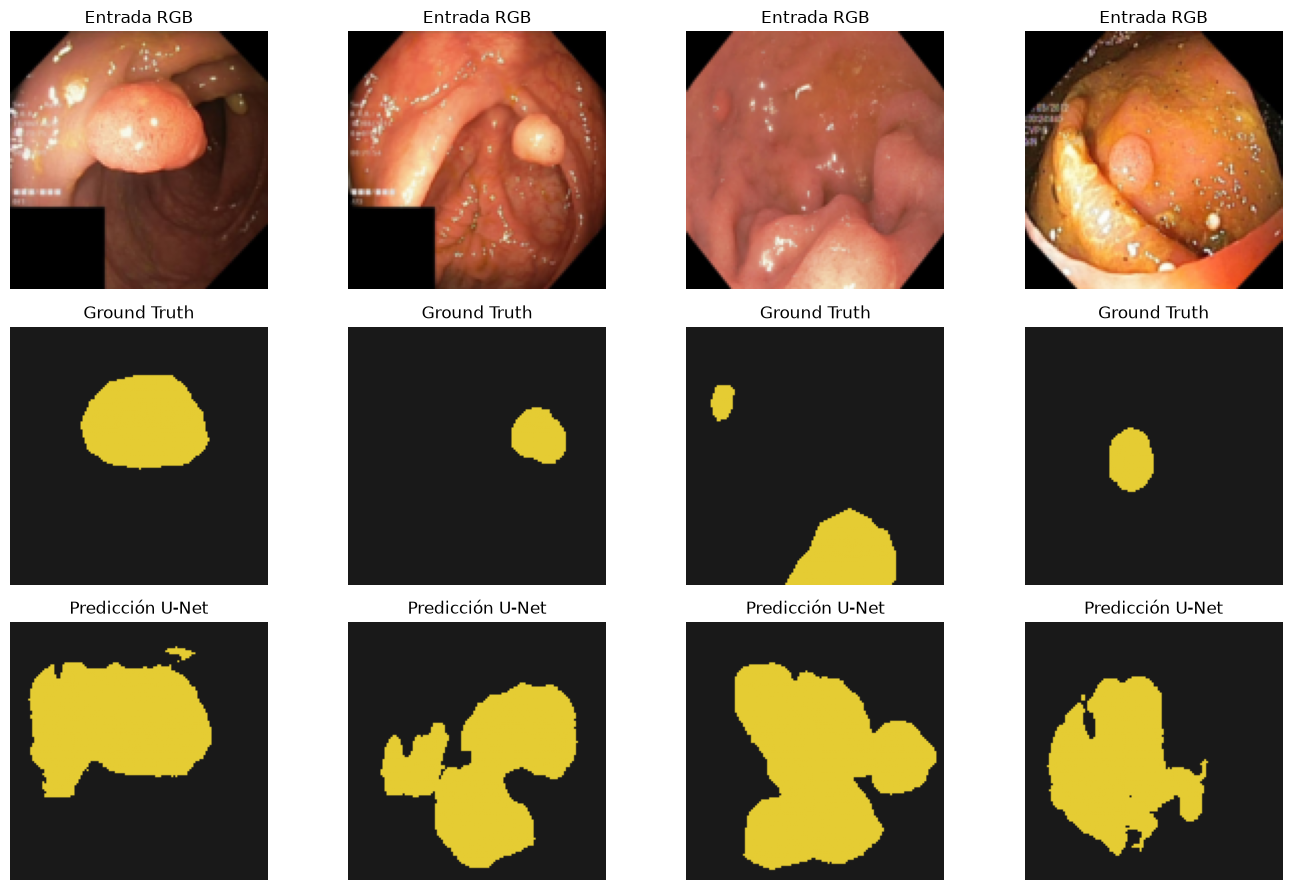

In [15]:
imgs, masks = next(iter(va_k))
modelo_k.eval()
with torch.no_grad():
    preds = modelo_k(imgs.to(DEVICE)).argmax(dim=1).cpu()

fig, axs = plt.subplots(3, 4, figsize=(14, 9))
for i in range(4):
    axs[0, i].imshow(desnormalizar(imgs[i])); axs[0, i].set_title("Entrada RGB")
    axs[1, i].imshow(PALETA_K[masks[i].numpy()]); axs[1, i].set_title("Ground Truth")
    axs[2, i].imshow(PALETA_K[preds[i].numpy()]); axs[2, i].set_title("Predicción U-Net")
for ax in axs.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()

**Resultado en Kvasir-SEG.** La misma U-Net (con `num_classes=2`) y la misma pérdida CE + Dice, entrenada 6 épocas con 800 imágenes, da IoU de 0.801 para `Fondo` y **0.421** para `Pólipo` (mIoU 0.611) en 200 imágenes de validación. Los pólipos son pequeños y de aspecto variable, ocupan 15.4 % de los píxeles, y 6 épocas en CPU son pocas, por lo que el IoU de la clase minoritaria queda lejos del de fondo. Se confirma lo visto antes: la exactitud (0.826) queda por debajo de la de predecir todo fondo (0.846), así que no sirve para evaluar este problema.

Carvana no se ejecutó: requiere credenciales de Kaggle (ver nota arriba).